In [2]:
from google.colab import files
uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [4]:
import pandas as pd

df = pd.read_csv('Dataset.csv')

print("Dataset uploaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset uploaded successfully!
Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
df = df.copy()

print("Duplicate records:", df.duplicated().sum())
df = df.drop_duplicates()

df['date_added'] = pd.to_datetime(
    df['date_added'],
    format='mixed',
    errors='coerce'
)

text_columns = ['type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']

for col in text_columns:
    df[col] = df[col].fillna('Unknown').astype(str).str.strip()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

display(df.head())


Duplicate records: 0

Missing values after cleaning:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Cleaned Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [6]:
df['added_year'] = df['date_added'].dt.year
df['added_month'] = df['date_added'].dt.month

df['content_age'] = df['date_added'].dt.year - df['release_year']

df['genre_count'] = df['listed_in'].apply(
    lambda x: len(x.split(','))
)

df['country_count'] = df['country'].apply(
    lambda x: len(x.split(','))
)

df['duration_value'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

df['is_movie'] = (df['type'] == 'Movie').astype(int)

df['is_tv_show'] = (df['type'] == 'TV Show').astype(int)

new_features = [
    'added_year',
    'added_month',
    'content_age',
    'genre_count',
    'country_count',
    'duration_value',
    'is_movie',
    'is_tv_show'
]

display(df[new_features].head())

print("New features created:", len(new_features))
print("Updated dataset shape:", df.shape)


,added_year,added_month,content_age,genre_count,country_count,duration_value,is_movie,is_tv_show
0,2021,9,1,1,1,90,1,0
1,2021,9,0,3,1,1,0,1
2,2021,9,0,3,1,1,0,1
3,2021,9,0,2,1,91,1,0
4,2021,9,28,3,1,125,1,0


New features created: 8
Updated dataset shape: (8790, 18)


In [7]:
df['success_score'] = 0

df['success_score'] += (df['content_age'] <= 5).astype(int) * 2

df['success_score'] += df['rating'].isin(['TV-MA', 'TV-14']).astype(int) * 2

df['success_score'] += (df['genre_count'] >= 2).astype(int)

df['success_score'] += (df['country_count'] >= 2).astype(int)

df['success_score'] += (
    (df['is_movie'] == 1) &
    (df['duration_value'] >= 100)
).astype(int)

df['success_score'] += (
    (df['is_tv_show'] == 1) &
    (df['duration_value'] >= 2)
).astype(int)

df['success_category'] = pd.cut(
    df['success_score'],
    bins=[-1, 2, 5, 8],
    labels=['Low', 'Medium', 'High']
)

print("Success Score Distribution:")
print(df['success_score'].value_counts().sort_index())

print("\nSuccess Category Distribution:")
print(df['success_category'].value_counts())

display(df[['title', 'success_score', 'success_category']].head(10))

Success Score Distribution:
success_score
0     180
1     494
2    1155
3    1392
4    1817
5    2130
6    1622
Name: count, dtype: int64

Success Category Distribution:
success_category
Medium    5339
Low       1829
High      1622
Name: count, dtype: int64


,title,success_score,success_category
0,Dick Johnson Is Dead,2,Low
1,Ganglands,5,Medium
2,Midnight Mass,5,Medium
3,Confessions of an Invisible Girl,3,Medium
4,Sankofa,4,Medium
5,The Great British Baking Show,6,High
6,The Starling,4,Medium
7,Motu Patlu in the Game of Zones,3,Medium
8,Je Suis Karl,6,High
9,Motu Patlu in Wonderland,1,Low


In [10]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

features = [
    'type',
    'release_year',
    'added_year',
    'added_month',
    'content_age',
    'genre_count',
    'country_count',
    'duration_value',
    'is_movie',
    'is_tv_show',
    'rating'
]

X = df[features].copy()

y = df['success_category']

label_encoders = {}

for col in ['type', 'rating']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Number of features:", X.shape[1])
print("Target classes:", target_encoder.classes_)


Training data shape: (7032, 11)
Testing data shape: (1758, 11)
Number of features: 11
Target classes: ['High' 'Low' 'Medium']


In [11]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("Accuracy:", round(accuracy * 100, 2), "%")

model_results = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(model_results.sort_values(by='F1 Score', ascending=False))


Training Random Forest...
Accuracy: 98.81 %

Training Gradient Boosting...
Accuracy: 98.98 %

Training Logistic Regression...
Accuracy: 62.06 %

MODEL PERFORMANCE COMPARISON


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1 Score
1,Gradient Boosting,0.989761,0.989842,0.989761,0.989748
0,Random Forest,0.988055,0.988199,0.988055,0.988029
2,Logistic Regression,0.620592,0.682187,0.620592,0.621513


GRADIENT BOOSTING - CLASSIFICATION REPORT

              precision    recall  f1-score   support

        High       0.98      1.00      0.99       324
         Low       1.00      0.97      0.98       366
      Medium       0.99      0.99      0.99      1068

    accuracy                           0.99      1758
   macro avg       0.99      0.99      0.99      1758
weighted avg       0.99      0.99      0.99      1758



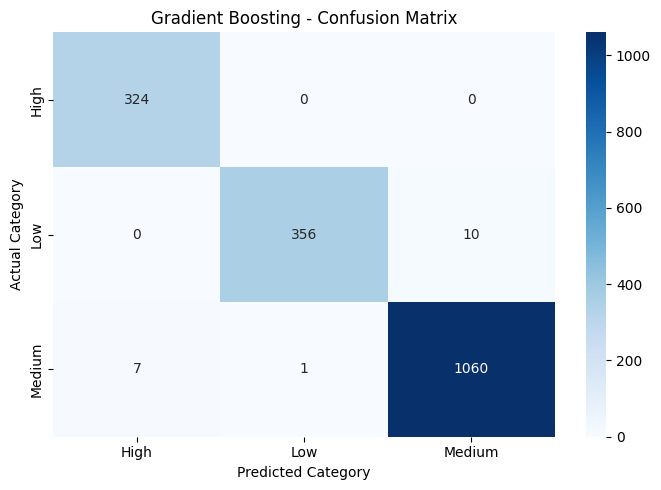

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_model = trained_models['Gradient Boosting']

y_pred = best_model.predict(X_test)

print("GRADIENT BOOSTING - CLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=target_encoder.classes_
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    'release_year',
    'content_age',
    'genre_count',
    'country_count',
    'duration_value'
]

X_cluster = df[cluster_features].copy()

X_cluster = X_cluster.replace([np.inf, -np.inf], np.nan)
X_cluster = X_cluster.fillna(X_cluster.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['content_cluster'] = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(X_scaled, df['content_cluster'])

print("K-Means Content Segmentation Completed!")
print("Number of Clusters:", df['content_cluster'].nunique())
print("Silhouette Score:", round(silhouette, 4))

print("\nCluster Distribution:")
print(df['content_cluster'].value_counts().sort_index())


K-Means Content Segmentation Completed!
Number of Clusters: 4
Silhouette Score: 0.4341

Cluster Distribution:
content_cluster
0     627
1    2221
2    1883
3    4059
Name: count, dtype: int64


In [14]:
cluster_summary = df.groupby('content_cluster').agg(
    total_titles=('title', 'count'),
    average_release_year=('release_year', 'mean'),
    average_content_age=('content_age', 'mean'),
    average_genres=('genre_count', 'mean'),
    average_countries=('country_count', 'mean'),
    average_duration=('duration_value', 'mean')
).round(2)

print("CONTENT CLUSTER ANALYSIS")
display(cluster_summary)

CONTENT CLUSTER ANALYSIS


,total_titles,average_release_year,average_content_age,average_genres,average_countries,average_duration
content_cluster,,,,,,
0,627,1988.52,30.56,2.24,1.0,107.03
1,2221,2017.19,1.73,2.60,1.0,3.52
2,1883,2016.50,2.20,1.00,1.0,57.94
3,4059,2015.43,3.47,2.52,1.0,106.11


In [15]:
cluster_type_analysis = pd.crosstab(
    df['content_cluster'],
    df['type']
)

print("CONTENT TYPE DISTRIBUTION BY CLUSTER")
display(cluster_type_analysis)

cluster_type_percentage = pd.crosstab(
    df['content_cluster'],
    df['type'],
    normalize='index'
).mul(100).round(2)

print("CONTENT TYPE PERCENTAGE")
display(cluster_type_percentage)

CONTENT TYPE DISTRIBUTION BY CLUSTER


type,Movie,TV Show
content_cluster,,
0,581,46
1,118,2103
2,1368,515
3,4059,0


CONTENT TYPE PERCENTAGE


type,Movie,TV Show
content_cluster,,
0,92.66,7.34
1,5.31,94.69
2,72.65,27.35
3,100.00,0.00


In [16]:
movie_df = df[df['type'] == 'Movie'].copy()
tv_df = df[df['type'] == 'TV Show'].copy()

print("Movie Records:", len(movie_df))
print("TV Show Records:", len(tv_df))

print("\nMovie Duration Statistics:")
display(movie_df['duration_value'].describe().round(2))

print("\nTV Show Season Statistics:")
display(tv_df['duration_value'].describe().round(2))

Movie Records: 6126
TV Show Records: 2664

Movie Duration Statistics:


,duration_value
count,6126.00
mean,99.58
std,28.28
min,3.00
25%,87.00
50%,98.00
75%,114.00
max,312.00



TV Show Season Statistics:


,duration_value
count,2664.00
mean,1.75
std,1.55
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,17.00


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

movie_features = [
    'release_year',
    'content_age',
    'genre_count',
    'duration_value'
]

X_movie = movie_df[movie_features].copy()

X_movie = X_movie.replace([np.inf, -np.inf], np.nan)
X_movie = X_movie.fillna(X_movie.median())

movie_scaler = StandardScaler()
X_movie_scaled = movie_scaler.fit_transform(X_movie)

movie_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

movie_df['movie_cluster'] = movie_kmeans.fit_predict(X_movie_scaled)

movie_silhouette = silhouette_score(
    X_movie_scaled,
    movie_df['movie_cluster']
)

print("MOVIE CLUSTERING COMPLETED")
print("Number of Clusters:", movie_df['movie_cluster'].nunique())
print("Silhouette Score:", round(movie_silhouette, 4))

print("\nMovie Cluster Distribution:")
print(movie_df['movie_cluster'].value_counts().sort_index())

MOVIE CLUSTERING COMPLETED
Number of Clusters: 3
Silhouette Score: 0.3476

Movie Cluster Distribution:
movie_cluster
0    3088
1    2486
2     552
Name: count, dtype: int64


In [18]:
movie_cluster_summary = movie_df.groupby('movie_cluster').agg(
    total_movies=('title', 'count'),
    average_release_year=('release_year', 'mean'),
    average_content_age=('content_age', 'mean'),
    average_genres=('genre_count', 'mean'),
    average_duration=('duration_value', 'mean')
).round(2)

print("MOVIE CLUSTER ANALYSIS")
display(movie_cluster_summary)

MOVIE CLUSTER ANALYSIS


,total_movies,average_release_year,average_content_age,average_genres,average_duration
movie_cluster,,,,,
0,3088,2015.03,3.92,2.68,112.25
1,2486,2016.33,2.33,1.46,80.06
2,552,1987.98,31.18,2.31,116.64


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

tv_features = [
    'release_year',
    'content_age',
    'genre_count',
    'duration_value'
]

X_tv = tv_df[tv_features].copy()

X_tv = X_tv.replace([np.inf, -np.inf], np.nan)
X_tv = X_tv.fillna(X_tv.median())

tv_scaler = StandardScaler()
X_tv_scaled = tv_scaler.fit_transform(X_tv)

tv_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

tv_df['tv_cluster'] = tv_kmeans.fit_predict(X_tv_scaled)

tv_silhouette = silhouette_score(
    X_tv_scaled,
    tv_df['tv_cluster']
)

print("TV SHOW CLUSTERING COMPLETED")
print("Number of Clusters:", tv_df['tv_cluster'].nunique())
print("Silhouette Score:", round(tv_silhouette, 4))

print("\nTV Show Cluster Distribution:")
print(tv_df['tv_cluster'].value_counts().sort_index())

TV SHOW CLUSTERING COMPLETED
Number of Clusters: 3
Silhouette Score: 0.3944

TV Show Cluster Distribution:
tv_cluster
0    1289
1    1265
2     110
Name: count, dtype: int64


In [20]:
tv_cluster_summary = tv_df.groupby('tv_cluster').agg(
    total_shows=('title', 'count'),
    average_release_year=('release_year', 'mean'),
    average_content_age=('content_age', 'mean'),
    average_genres=('genre_count', 'mean'),
    average_seasons=('duration_value', 'mean')
).round(2)

print("TV SHOW CLUSTER ANALYSIS")
display(tv_cluster_summary)

TV SHOW CLUSTER ANALYSIS


,total_shows,average_release_year,average_content_age,average_genres,average_seasons
tv_cluster,,,,,
0,1289,2017.47,1.39,3.00,1.59
1,1265,2017.50,1.56,1.61,1.82
2,110,1996.74,21.49,1.88,2.88


In [21]:
print("========== NETFLIX CONTENT INSIGHTS ==========")

print("\nMOVIE INSIGHTS")

for cluster_id, row in movie_cluster_summary.iterrows():
    print(
        f"Movie Cluster {cluster_id}: "
        f"{row['total_movies']} titles, "
        f"average release year {row['average_release_year']}, "
        f"average duration {row['average_duration']} minutes."
    )

print("\nTV SHOW INSIGHTS")

for cluster_id, row in tv_cluster_summary.iterrows():
    print(
        f"TV Cluster {cluster_id}: "
        f"{row['total_shows']} shows, "
        f"average release year {row['average_release_year']}, "
        f"average seasons {row['average_seasons']}."
    )

print("\nOVERALL DATASET INSIGHTS")
print("Total Netflix Titles:", len(df))
print("Total Movies:", len(movie_df))
print("Total TV Shows:", len(tv_df))

print("\nMovie Silhouette Score:", round(movie_silhouette, 4))
print("TV Show Silhouette Score:", round(tv_silhouette, 4))

print("\nBusiness insight generation completed!")

========== NETFLIX CONTENT INSIGHTS ==========

MOVIE INSIGHTS
Movie Cluster 0: 3088.0 titles, average release year 2015.03, average duration 112.25 minutes.
Movie Cluster 1: 2486.0 titles, average release year 2016.33, average duration 80.06 minutes.
Movie Cluster 2: 552.0 titles, average release year 1987.98, average duration 116.64 minutes.

TV SHOW INSIGHTS
TV Cluster 0: 1289.0 shows, average release year 2017.47, average seasons 1.59.
TV Cluster 1: 1265.0 shows, average release year 2017.5, average seasons 1.82.
TV Cluster 2: 110.0 shows, average release year 1996.74, average seasons 2.88.

OVERALL DATASET INSIGHTS
Total Netflix Titles: 8790
Total Movies: 6126
Total TV Shows: 2664

Movie Silhouette Score: 0.3476
TV Show Silhouette Score: 0.3944

Business insight generation completed!


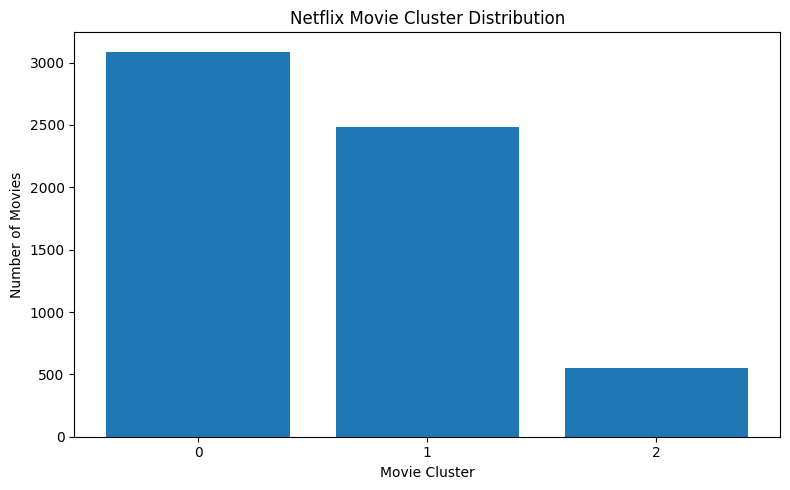

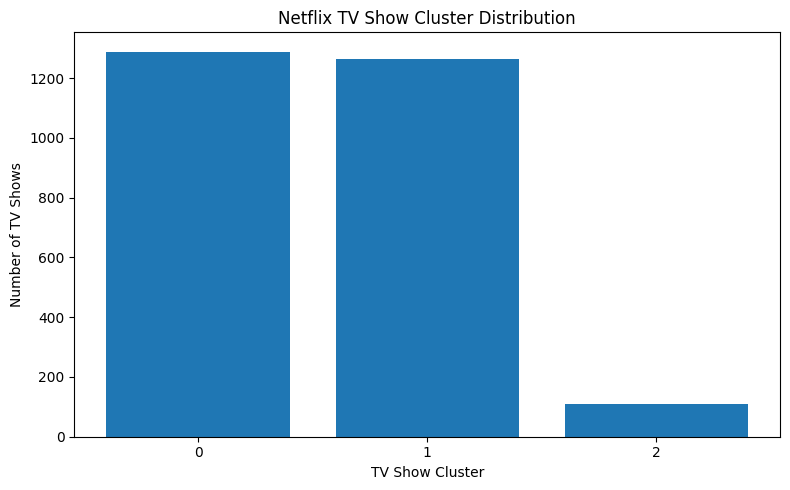

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

movie_counts = movie_df['movie_cluster'].value_counts().sort_index()

plt.bar(
    movie_counts.index.astype(str),
    movie_counts.values
)

plt.title("Netflix Movie Cluster Distribution")
plt.xlabel("Movie Cluster")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

tv_counts = tv_df['tv_cluster'].value_counts().sort_index()

plt.bar(
    tv_counts.index.astype(str),
    tv_counts.values
)

plt.title("Netflix TV Show Cluster Distribution")
plt.xlabel("TV Show Cluster")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()

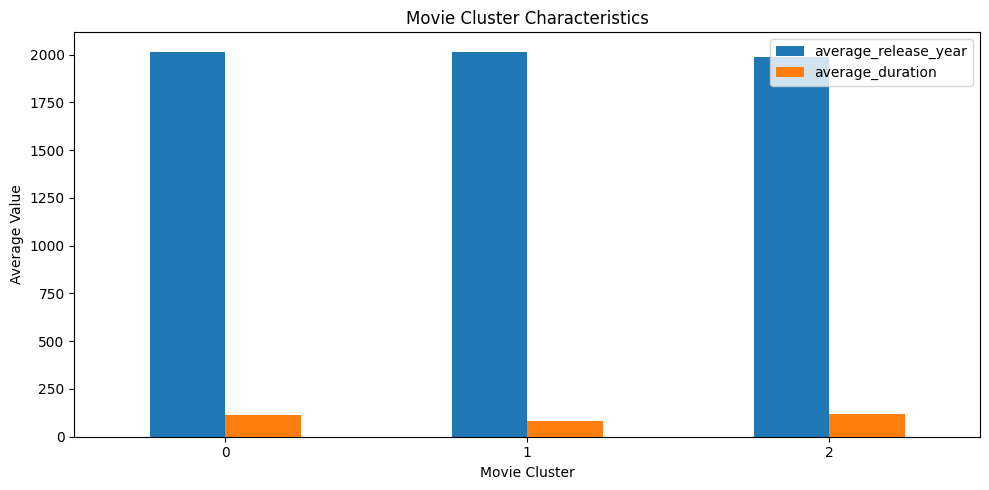

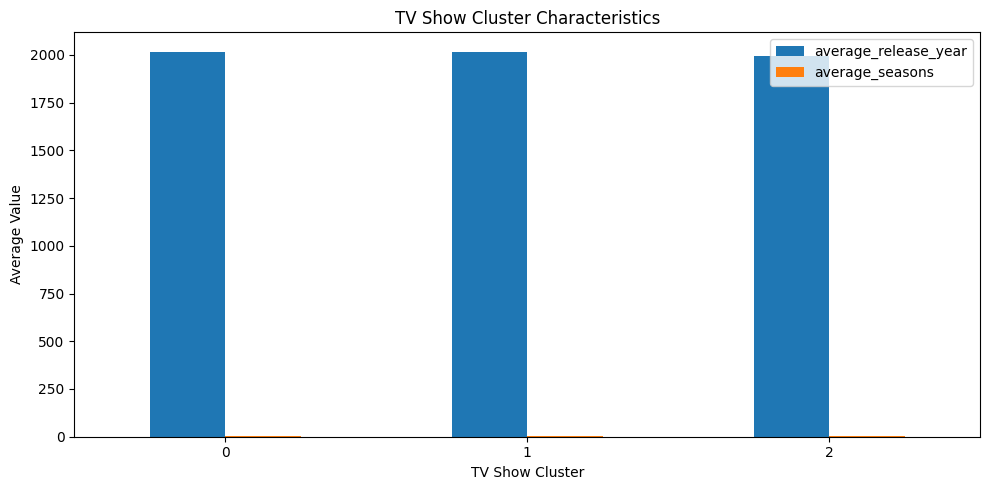

In [23]:
movie_cluster_summary[
    ['average_release_year', 'average_duration']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Movie Cluster Characteristics")
plt.xlabel("Movie Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


tv_cluster_summary[
    ['average_release_year', 'average_seasons']
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("TV Show Cluster Characteristics")
plt.xlabel("TV Show Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

movie_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clustering', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

tv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clustering', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

movie_pipeline.fit(movie_df[movie_features])
tv_pipeline.fit(tv_df[tv_features])

movie_df['pipeline_cluster'] = movie_pipeline.predict(
    movie_df[movie_features]
)

tv_df['pipeline_cluster'] = tv_pipeline.predict(
    tv_df[tv_features]
)

print("END-TO-END ML PIPELINES COMPLETED!")
print("Movie Pipeline:", movie_df['pipeline_cluster'].nunique(), "clusters")
print("TV Show Pipeline:", tv_df['pipeline_cluster'].nunique(), "clusters")

END-TO-END ML PIPELINES COMPLETED!
Movie Pipeline: 3 clusters
TV Show Pipeline: 3 clusters


In [25]:
movie_output = movie_df.copy()
tv_output = tv_df.copy()

movie_output['content_cluster'] = movie_output['pipeline_cluster']
tv_output['content_cluster'] = tv_output['pipeline_cluster']

final_df = pd.concat(
    [movie_output, tv_output],
    ignore_index=True
)

final_df.to_csv('Netflix_Content_Analysis.csv', index=False)

movie_cluster_summary.to_csv('Movie_Cluster_Insights.csv')
tv_cluster_summary.to_csv('TV_Show_Cluster_Insights.csv')

evaluation_df = pd.DataFrame({
    'Model': ['Movie K-Means', 'TV Show K-Means'],
    'Clusters': [3, 3],
    'Silhouette Score': [movie_silhouette, tv_silhouette]
})

evaluation_df.to_csv('Model_Evaluation.csv', index=False)

print("All project output files saved successfully!")
print("Final Dataset Shape:", final_df.shape)
display(evaluation_df)

All project output files saved successfully!
Final Dataset Shape: (8790, 24)


,Model,Clusters,Silhouette Score
0,Movie K-Means,3,0.347587
1,TV Show K-Means,3,0.394424


In [26]:
from google.colab import files
files.download('Netflix_Content_Analysis.csv')
files.download('Movie_Cluster_Insights.csv')
files.download('TV_Show_Cluster_Insights.csv')
files.download('Model_Evaluation.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import joblib

joblib.dump(movie_pipeline, 'Netflix_Movie_Clustering.pkl')

joblib.dump(tv_pipeline, 'Netflix_TV_Show_Clustering.pkl')

joblib.dump(
    {
        'movie_features': movie_features,
        'tv_features': tv_features
    },
    'Netflix_Feature_Information.pkl'
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [28]:
from google.colab import files
files.download('Netflix_Movie_Clustering.pkl')
files.download('Netflix_TV_Show_Clustering.pkl')
files.download('Netflix_Feature_Information.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>